# Week 1 EDA: the sampled application table

Work through the sections in order. Cells marked **PROVIDED** run as they are. For each
**TODO(student)** section, answer the question with code in the empty cell, then write one
or two sentences of what you see. Keep reusable code in `src/`; this notebook is for looking.

Run it from the repository root with `jupyter notebook` (or `jupyter lab`) after `python run.py sample`.

## 1. Load the sample  (PROVIDED)

In [1]:
# PROVIDED
import sys
from pathlib import Path

import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.data import load_application  # noqa: E402
from src.utils import load_config  # noqa: E402

config = load_config(ROOT / "config" / "config.yaml")
app = load_application(config)
print(app.shape)
app.head()

(5000, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100021,0,Revolving loans,F,N,Y,1,81000.0,270000.0,13500.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,100030,0,Cash loans,F,N,Y,0,90000.0,225000.0,11074.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100033,0,Cash loans,M,Y,Y,0,270000.0,790830.0,57676.5,...,0,0,0,0,0.0,0.0,0.0,1.0,0.0,1.0
3,100294,0,Cash loans,F,N,Y,0,157500.0,835380.0,35392.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
4,100322,0,Cash loans,M,Y,Y,2,225000.0,254700.0,26874.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


## 2. Target rate  (PROVIDED)

TARGET
0    4596
1     404
Name: count, dtype: int64
Default rate: 8.08%


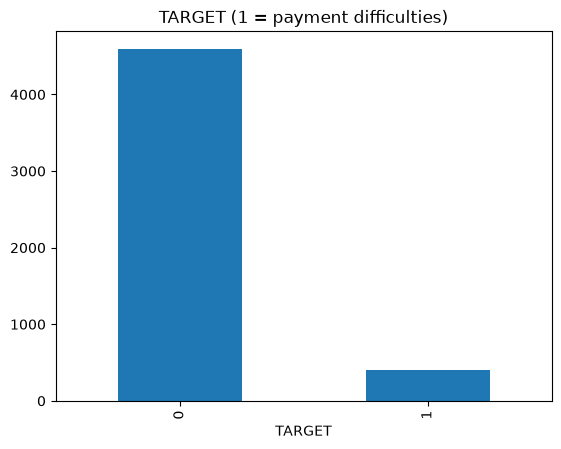

In [2]:
# PROVIDED
counts = app["TARGET"].value_counts().sort_index()
print(counts)
print(f"Default rate: {app['TARGET'].mean():.2%}")
counts.plot.bar(title="TARGET (1 = payment difficulties)")
plt.show()

## 3. Missingness  (TODO(student))

Which columns have the most missing values? How many columns are more than half empty?
Do the most-missing columns seem to belong together (look at their names)?

Columns with any missing values: 65 of 122
Columns more than half empty:    48

COMMONAREA_MODE             71.4%
COMMONAREA_AVG              71.4%
COMMONAREA_MEDI             71.4%
NONLIVINGAPARTMENTS_MODE    71.0%
NONLIVINGAPARTMENTS_AVG     71.0%
NONLIVINGAPARTMENTS_MEDI    71.0%
LIVINGAPARTMENTS_AVG        70.2%
LIVINGAPARTMENTS_MODE       70.2%
LIVINGAPARTMENTS_MEDI       70.2%
FONDKAPREMONT_MODE          70.1%
FLOORSMIN_MEDI              69.6%
FLOORSMIN_MODE              69.6%
FLOORSMIN_AVG               69.6%
YEARS_BUILD_MEDI            68.1%
YEARS_BUILD_AVG             68.1%

suffix
MODE     18
AVG      14
MEDI     14
other     2
Not building columns: ['OWN_CAR_AGE', 'EXT_SOURCE_1']


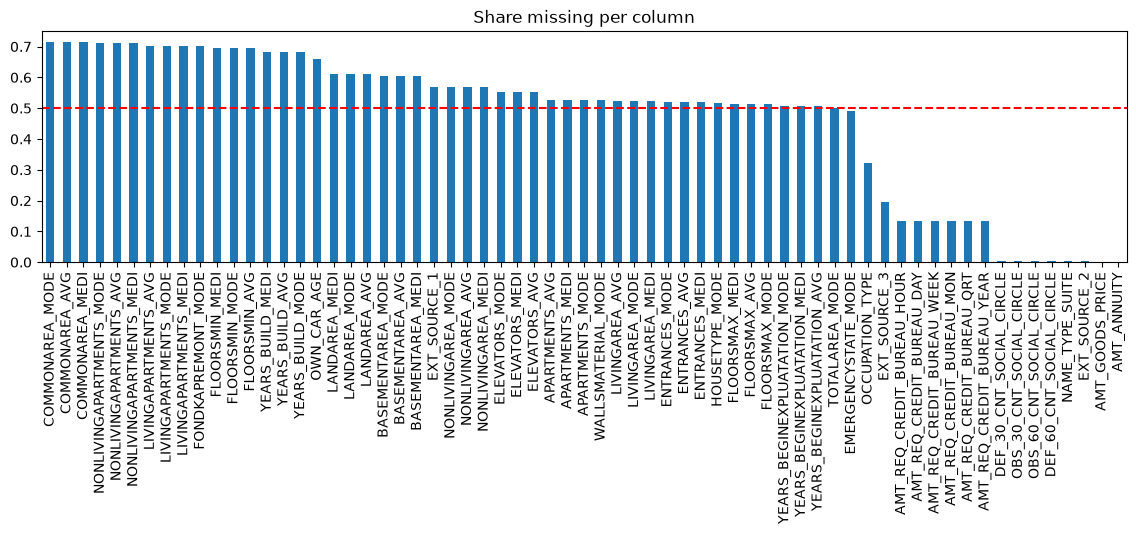

In [ ]:
missing = app.isna().mean().sort_values(ascending=False)
print(f"Columns with any missing values: {(missing > 0).sum()} of {app.shape[1]}")
print(f"Columns more than half empty:    {(missing > 0.5).sum()}")
print()
print(missing.head(15).map("{:.1%}".format).to_string())

half_empty = missing[missing > 0.5].index
suffix = half_empty.str.extract(r"_(AVG|MODE|MEDI)$")[0].fillna("other").rename("suffix")
print()
print(suffix.value_counts().to_string())
print("Not building columns:", list(half_empty[suffix.eq("other").to_numpy()]))

missing[missing > 0].plot.bar(figsize=(14, 3), title="Share missing per column")
plt.axhline(0.5, color="red", linestyle="--")
plt.show()

**Answer:** 65 of the 122 columns have empty cells, and **48 are more than half empty**. The worst ones are
`COMMONAREA_*`, `NONLIVINGAPARTMENTS_*` and `LIVINGAPARTMENTS_*` at about 70% missing. Nearly all of the 48 belong
together: they describe the applicant's building and come in `_AVG` / `_MODE` / `_MEDI` versions that are missing
on the same rows. The only other two are `OWN_CAR_AGE` and `EXT_SOURCE_1`. The model needs these filled, for example
with the median plus a "was missing" flag, because whether a value is missing may itself carry information.

## 4. The DAYS_EMPLOYED anomaly  (TODO(student))

Look at the distribution of `DAYS_EMPLOYED`. Which value looks impossible, and how many
applicants have it? Is the default rate of those applicants different from everyone else's?
What does that tell you about how to handle it?

count      5000.000000
mean      63622.116200
std      141057.282676
min      -15202.000000
25%       -2686.750000
50%       -1198.000000
75%        -305.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64

DAYS_EMPLOYED
 365243    897
-1413        6
-617         6
Name: count, dtype: int64

Applicants with 365243: 897 (17.9%)
Default rate, anomaly:  4.91%
Default rate, everyone else: 8.77%

Income type of the anomaly group:
NAME_INCOME_TYPE
Pensioner    897


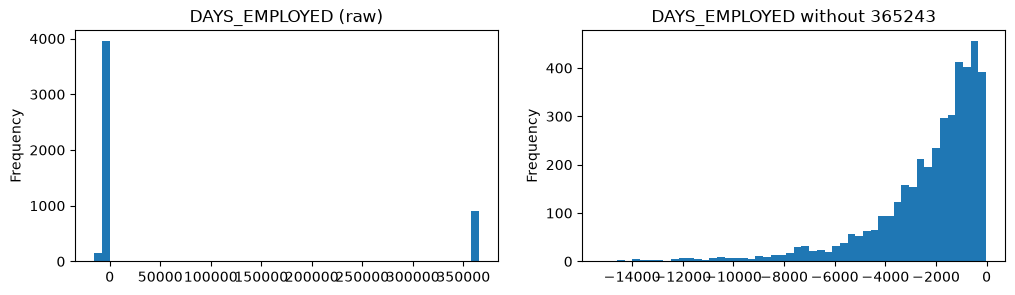

In [ ]:
print(app["DAYS_EMPLOYED"].describe())
print()
print(app["DAYS_EMPLOYED"].value_counts().head(3))

ANOMALY = 365243
is_anom = app["DAYS_EMPLOYED"] == ANOMALY
print(f"\nApplicants with {ANOMALY}: {is_anom.sum():,} ({is_anom.mean():.1%})")
print(f"Default rate, anomaly:  {app.loc[is_anom, 'TARGET'].mean():.2%}")
print(f"Default rate, everyone else: {app.loc[~is_anom, 'TARGET'].mean():.2%}")
print("\nIncome type of the anomaly group:")
print(app.loc[is_anom, "NAME_INCOME_TYPE"].value_counts().to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
app["DAYS_EMPLOYED"].plot.hist(bins=50, ax=axes[0], title="DAYS_EMPLOYED (raw)")
app.loc[~is_anom, "DAYS_EMPLOYED"].hist(bins=50, ax=axes[1])
axes[1].set_title(f"DAYS_EMPLOYED without {ANOMALY}")
plt.show()

**Answer:** The impossible value is **365243**. It is positive, which would mean employment starting about 1,000 years
*after* the application. **897 applicants (17.9%)** have it, and every one of them is a `Pensioner`, so it is a
placeholder for "not employed", not a real number of days. They default **less** than everyone else
(4.9% vs 8.8%). That makes the value informative, so it shouldn't be thrown away: in `clean_application` we replace it
with NaN and keep a 0/1 flag that marks these applicants.

## 5. Default rate by a categorical column  (TODO(student))

Pick one categorical column (for example `NAME_CONTRACT_TYPE`, `CODE_GENDER`, or
`OCCUPATION_TYPE`). Show the default rate and the number of applicants in each category.
Which differences would you trust, given how few applicants some categories have?

                              default_rate  applicants
NAME_EDUCATION_TYPE                                   
Secondary / secondary special         9.1%        3569
Higher education                      5.0%        1177
Incomplete higher                     5.9%         187
Lower secondary                      13.6%          66
Academic degree                       0.0%           1


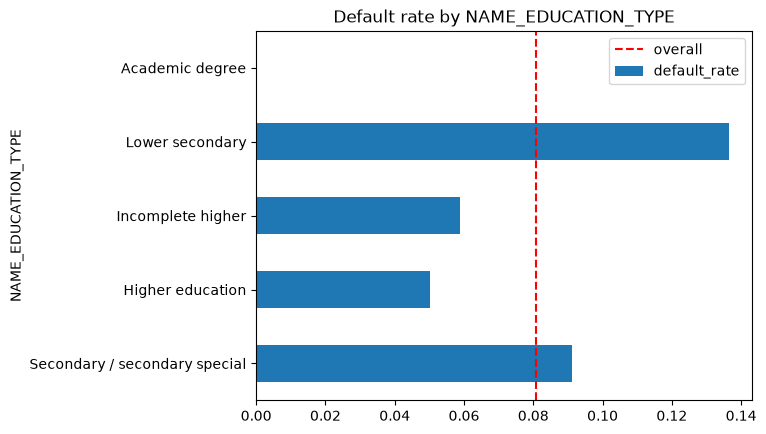

In [5]:
col = "NAME_EDUCATION_TYPE"
by_group = (app.groupby(col)["TARGET"]
               .agg(default_rate="mean", applicants="size")
               .sort_values("applicants", ascending=False))
print(by_group.assign(default_rate=by_group["default_rate"].map("{:.1%}".format)).to_string())

by_group["default_rate"].plot.barh(title=f"Default rate by {col}")
plt.axvline(app["TARGET"].mean(), color="red", linestyle="--", label="overall")
plt.legend()
plt.show()

**Answer:** Default rate goes down as education goes up. *Secondary* (3,569 people) defaults at 9.1%, *Higher
education* (1,177) at 5.0%, and *Lower secondary* at 13.6%. The first two groups are large, so I trust that gap. Lower
secondary has only 66 people, which is about 9 defaults, so its rate is a rough guess. *Academic degree* has
**1 person**, so its 0% means nothing. Before modeling, rare categories like this should be merged into
an "other" group.

## 6. Correlations with TARGET  (TODO(student))

Which numeric columns are most correlated with `TARGET` (positively and negatively)?
Remember the sign conventions: `DAYS_*` columns are negative numbers of days before the
application. Is a correlation of 0.1 large or small here?

Most negative (higher value -> fewer defaults):
EXT_SOURCE_2                   -0.189
EXT_SOURCE_1                   -0.183
EXT_SOURCE_3                   -0.161
AMT_GOODS_PRICE                -0.052
FLAG_PHONE                     -0.043
AMT_CREDIT                     -0.042
YEARS_BEGINEXPLUATATION_MEDI   -0.039
YEARS_BEGINEXPLUATATION_AVG    -0.039

Most positive (higher value -> more defaults):
FLAG_EMP_PHONE                 0.054
REGION_RATING_CLIENT           0.057
REGION_RATING_CLIENT_W_CITY    0.058
DAYS_LAST_PHONE_CHANGE         0.059
REG_CITY_NOT_WORK_CITY         0.067
REG_CITY_NOT_LIVE_CITY         0.068
DAYS_BIRTH                     0.083
DAYS_EMPLOYED                  0.096

DAYS_EMPLOYED with the placeholder left in: -0.053


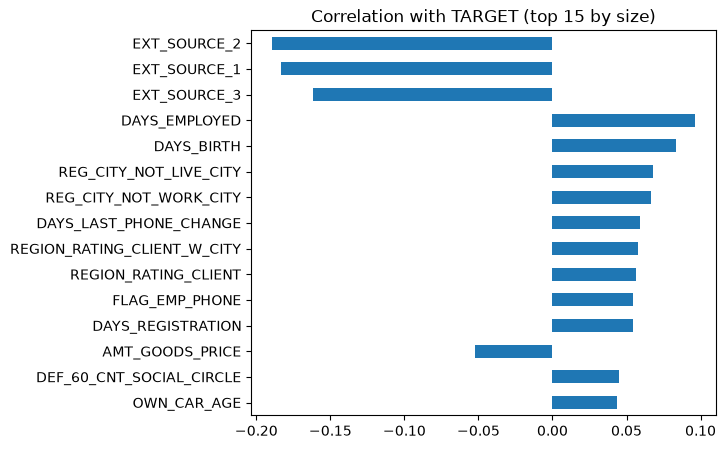

In [6]:
# Treat the 365243 placeholder as missing first; otherwise it flips the sign of DAYS_EMPLOYED
numeric = app.select_dtypes("number").drop(columns=["TARGET", "SK_ID_CURR"]).copy()
numeric = numeric.loc[:, numeric.nunique() > 1]  # a constant column has no correlation
numeric.loc[numeric["DAYS_EMPLOYED"] == ANOMALY, "DAYS_EMPLOYED"] = float("nan")
corr = numeric.corrwith(app["TARGET"]).dropna().sort_values()

print("Most negative (higher value -> fewer defaults):")
print(corr.head(8).round(3).to_string())
print("\nMost positive (higher value -> more defaults):")
print(corr.tail(8).round(3).to_string())
raw = app["DAYS_EMPLOYED"].corr(app["TARGET"])
print(f"\nDAYS_EMPLOYED with the placeholder left in: {raw:.3f}")

top = corr.abs().sort_values().tail(15).index
corr[top].plot.barh(figsize=(6, 5), title="Correlation with TARGET (top 15 by size)")
plt.show()

**Answer:** The three outside credit scores, `EXT_SOURCE_2` (-0.19), `EXT_SOURCE_1` (-0.18) and `EXT_SOURCE_3`
(-0.16), are the strongest by a wide margin: higher score, fewer defaults. On the positive side are `DAYS_EMPLOYED`
(+0.10) and `DAYS_BIRTH` (+0.08). These are negative numbers, so a higher value means a shorter job or a
younger applicant, and those people default more. If the 365243 placeholder is left in, `DAYS_EMPLOYED` shows -0.05 with
the wrong sign, which shows why the fix matters. No column goes above 0.2. For a rare 0/1 target like this, 0.1 is
a meaningful signal, but no single column predicts defaults well alone.

## 7. Findings

- **Defaults are rare: 8.1% of the 5,000 applicants.** A model that always says "no default" would be 92% accurate
We don't use accuracy to evaluate the baseline because it's not very helpful, so instead we use ROC AUC and KS to get a better sense of how it's doing.
- **Missing data is concentrated:** 65 of 122 columns have gaps, and 48 are more than half empty. Almost all of those
are building-description columns (`_AVG`/`_MODE`/`_MEDI` triples that go missing together), plus `OWN_CAR_AGE` and
`EXT_SOURCE_1`. The baseline needs imputation, and a missing-value flag may help.
- **`DAYS_EMPLOYED = 365243` is a placeholder, not a value:** it covers 897 applicants (17.9%), all pensioners, and they
default at 4.9% vs 8.8% for everyone else. In `clean_application` we replace it with NaN and keep a flag. Leaving it in
This thing can actually change the direction of how closely a column is related to the target.
- **One of the most important indicators is the outside credit scores, specifically `EXT_SOURCE_1`, `EXT_SOURCE_2`, and `EXT_SOURCE_3`**. These scores have a strong connection, with correlations ranging from -0.16 to -0.19, making them a key signal.
Younger applicants and people in shorter jobs default more. Every correlation is under 0.2, so the model has to
combine many weak signals.
- **Categories show real but uneven differences:** default rate falls from 13.6% (lower secondary) to 5.0% (higher
education), but some groups are tiny (Academic degree has 1 person). Rare categories should be grouped before
one-hot encoding so the model doesn't learn noise.